In [1]:
import numpy,pandas,json,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [2]:
# Load in data
## Data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data,arctic_cd_data,northsea_cd_data,kheu_cd_data = split_data_by_site(d114cd_data)

# Collate the ages
ages = d114cd_data["Age model"].values

# Load in GP
d114cd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON(data_directory+"/output/d13c_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]


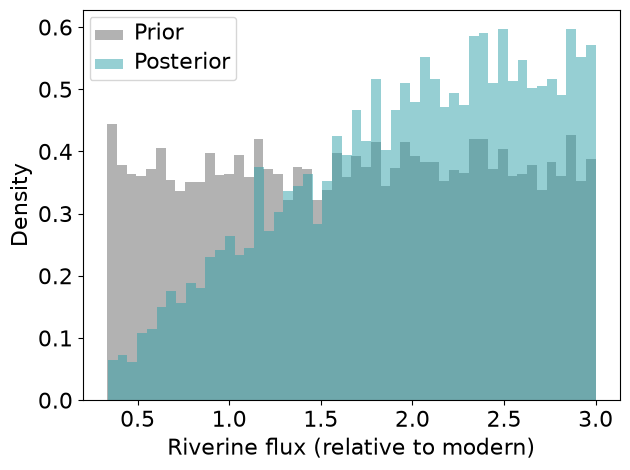

In [3]:
original_input = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['input_multiplier']
prior_initial_input = numpy.array([model["input_mass"][0]/30000000.0 for model in prior_results])
posterior_initial_input = numpy.array([model["input_mass"][0]/30000000.0 for model in posterior_results])


figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=50,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Riverine flux (relative to modern)")
axes.set_ylabel("Density")

axes.legend(["Prior","Posterior"])
# # Legend
# axes.legend([handle_0,handle_1],["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_input_flux.png",transparent=True)

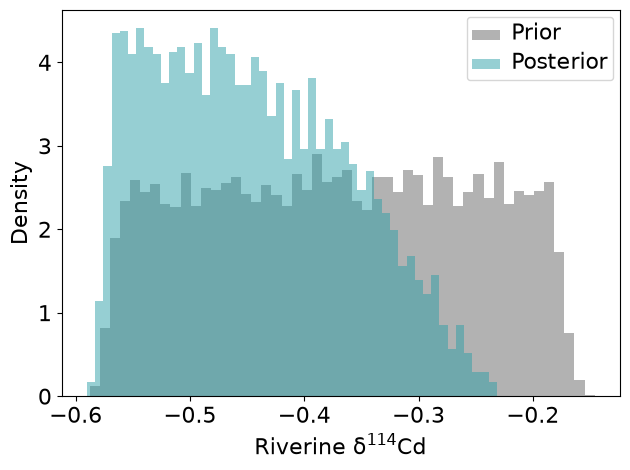

In [4]:
original_input_isotopes = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['input_isotopes']
prior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in prior_results])
posterior_initial_input_isotopes = numpy.array([model["input_δ114Cd"][0] for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
# axes.hist(prior_initial_input_isotopes,bins=100,density=True,color="#94babd",alpha=0.5)
axes.hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)

axes.set_xlabel("Riverine δ$^{114}$Cd")
axes.set_ylabel("Density")

# # Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_input_isotopes.png",transparent=True)

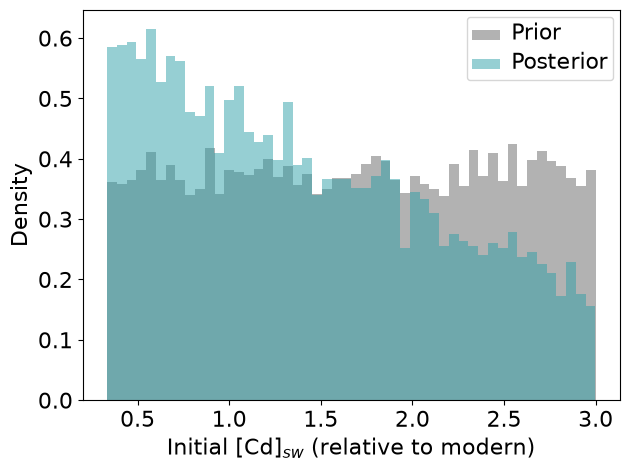

In [5]:
original_seawater_mass = json.load(open(data_directory+'/output/original_initial_conditions.json','r'))['mass_multiplier']
prior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in prior_results])
posterior_initial_seawater_mass = numpy.array([model["seawater_mass"][0]/8.36e11 for model in posterior_results])

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_seawater_mass,bins=50,color="#666666",alpha=0.5,density=True)
# axes.hist(prior_initial_seawater_mass,bins=20,color="#94babd",alpha=0.3)
axes.hist(posterior_initial_seawater_mass,bins=50,color="#2ea0a8",alpha=0.5,density=True)


axes.set_xlabel("Initial [Cd]$_{sw}$ (relative to modern)")
axes.set_ylabel("Density")

# Legend
axes.legend(["Prior","Posterior"])

# Change the font size
for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_seawater_mass.png",transparent=True)

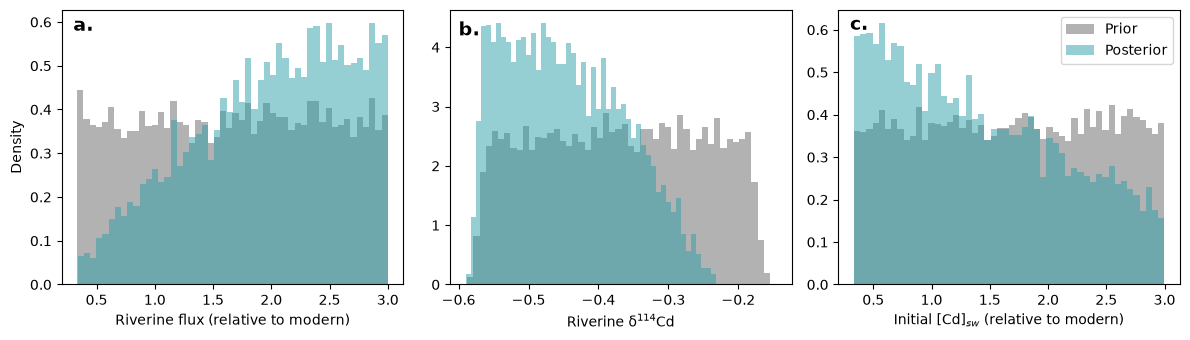

In [ ]:
# Plot all three as subplots
figure,axes = pyplot.subplots(1,3,figsize=(12,3.5))

axes[0].hist(original_input,bins=50,density=True,color="#666666",alpha=0.5)
axes[0].hist(posterior_initial_input,bins=50,density=True,color="#2ea0a8",alpha=0.5)
axes[0].text(0.3,0.58, "a.",fontsize=14,fontweight="bold")

axes[0].set_xlabel("Riverine flux (relative to modern)")
axes[0].set_ylabel("Density")

axes[1].hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
axes[1].hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)
axes[1].text(-0.6,4.2, "b.",fontsize=14,fontweight="bold")

axes[1].set_xlabel("Riverine δ$^{114}$Cd")

axes[2].hist(original_seawater_mass,bins=50,color="#666666",alpha=0.5,density=True)
axes[2].hist(posterior_initial_seawater_mass,bins=50,color="#2ea0a8",alpha=0.5,density=True)
axes[2].text(0.3,0.6, "c.",fontsize=14,fontweight="bold")

axes[2].set_xlabel("Initial [Cd]$_{sw}$ (relative to modern)")

# Legend
axes[2].legend(["Prior","Posterior"])

figure.tight_layout()
# figure.savefig("../../figures/cadmium_initial_conditions_bayesian.png",transparent=True)
# figure.savefig("../../figures/figure_6.svg",transparent=True,dpi=600)

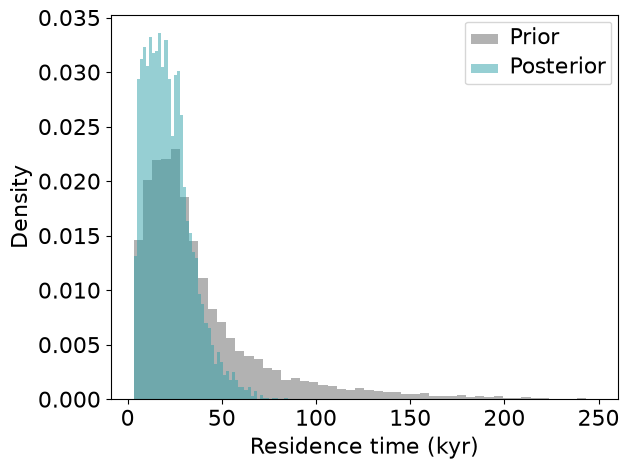

In [10]:
# Residence time
original_seawater_fullmass = numpy.array(original_seawater_mass)*8.36e11
prior_initial_seawater_fullmass = numpy.array(prior_initial_seawater_mass)*8.36e11
posterior_initial_seawater_fullmass = numpy.array(posterior_initial_seawater_mass)*8.36e11

original_input_fullmass = numpy.array(original_input)*3e7
prior_initial_input_fullmass = numpy.array(prior_initial_input)*3e7
posterior_initial_input_fullmass = numpy.array(posterior_initial_input)*3e7

original_residence_time = list(numpy.array(original_seawater_fullmass)/numpy.array(original_input_fullmass) * 1e-3)
prior_residence_time = list(numpy.array(prior_initial_seawater_fullmass)/numpy.array(prior_initial_input_fullmass)* 1e-3)
posterior_residence_time = list(numpy.array(posterior_initial_seawater_fullmass)/numpy.array(posterior_initial_input_fullmass)* 1e-3)

figure = pyplot.figure()
axes = figure.add_subplot(111)

axes.hist(original_residence_time,bins=50,color="#666666",alpha=0.5,density=True)
# axes.hist(prior_residence_time,bins=20,color="#94babd",alpha=0.3)
axes.hist(posterior_residence_time,bins=50,color="#2ea0a8",alpha=0.5,density=True)

axes.set_xlabel("Residence time (kyr)")
axes.set_ylabel("Density")

axes.legend(["Prior","Posterior"])

for item in ([axes.title, axes.xaxis.label, axes.yaxis.label] +
             axes.get_xticklabels() + axes.get_yticklabels() + axes.get_legend().get_texts()):
    item.set_fontsize(16)

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_residence_time.png",transparent=True)

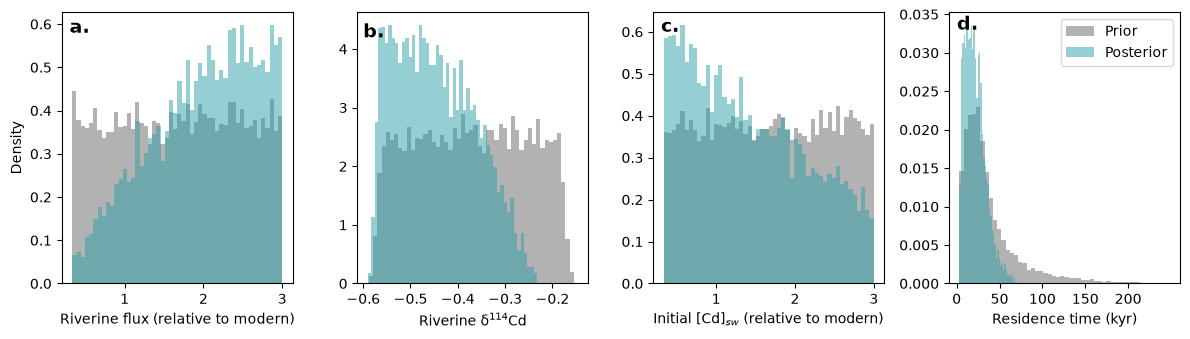

In [17]:
# Plot all three as subplots
figure,axes = pyplot.subplots(1,4,figsize=(12,3.5))

axes[0].hist(original_input,bins=50,density=True,color="#666666",alpha=0.5)
axes[0].hist(posterior_initial_input,bins=50,density=True,color="#2ea0a8",alpha=0.5)
axes[0].text(0.3,0.58, "a.",fontsize=14,fontweight="bold")

axes[0].set_xlabel("Riverine flux (relative to modern)")
axes[0].set_ylabel("Density")

axes[1].hist(original_input_isotopes,bins=50,density=True,color="#666666",alpha=0.5)
axes[1].hist(posterior_initial_input_isotopes,bins=50,density=True,color="#2ea0a8",alpha=0.5)
axes[1].text(-0.6,4.2, "b.",fontsize=14,fontweight="bold")

axes[1].set_xlabel("Riverine δ$^{114}$Cd")

axes[2].hist(original_seawater_mass,bins=50,color="#666666",alpha=0.5,density=True)
axes[2].hist(posterior_initial_seawater_mass,bins=50,color="#2ea0a8",alpha=0.5,density=True)
axes[2].text(0.3,0.6, "c.",fontsize=14,fontweight="bold")

axes[2].set_xlabel("Initial [Cd]$_{sw}$ (relative to modern)")

axes[3].hist(original_residence_time,bins=50,color="#666666",alpha=0.5,density=True)
axes[3].hist(posterior_residence_time,bins=50,color="#2ea0a8",alpha=0.5,density=True)
axes[3].text(0.3,0.033, "d.",fontsize=14,fontweight="bold")

axes[3].set_xticks([0, 50, 100, 150, 200])

axes[3].set_xlabel("Residence time (kyr)")


# Legend
axes[3].legend(["Prior","Posterior"])

figure.tight_layout()
figure.savefig("../../figures/cadmium_initial_conditions_bayesian.png",transparent=True)
figure.savefig("../../figures/figure_6.svg",transparent=True,dpi=600)